# Novedades de NAcAL: versiones 0.3.0 y 0.4.0

Este cuaderno muestra lo añadido en noviembre de 2026:

1. La función `desarrollo` (versión 0.3.0): procesos de eliminación en varias líneas, compactos o abreviados.
2. La función `idioma` (versión 0.3.0): textos de salida en español o en inglés.
3. Tres fallos corregidos (versión 0.3.0).
4. La clase `Polinomio` (versión 0.4.0): eliminación y sistemas de ecuaciones con polinomios.

La primera celda hace que el cuaderno use la copia de trabajo del repositorio en lugar de la versión instalada, e indica cuál es. La parte 4 necesita la versión 0.4.0 o posterior.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1]))   # raíz del repositorio nacallib

import nacal
print('NAcAL', nacal.__version__, '-', nacal.__file__)

from nacal import *
from IPython.display import Math
x, a, b, c, d = sympy.symbols('x a b c d')
print('Clase Polinomio disponible:', 'Polinomio' in globals())

NAcAL 0.4.0 - /home/marcos/SynologyDrive/ReposGH/Docencia/nacallib/nacal/__init__.py
Clase Polinomio disponible: True


## 1. La función `desarrollo`

El atributo `tex` de cualquier resultado de una eliminación (`Elim`, `SEL`, `Homogenea`, `InvMat`, `Determinante`...) contiene todo el proceso en una única fórmula, que a menudo no cabe en la página. `desarrollo` recompone ese código sin repetir los cálculos.

Sin opciones devuelve el código tal cual:

In [2]:
A = Matrix([ [0,2,2], [1,-2,-8], [1,1,1] ])
E = ElimGJ(A)
print(desarrollo(E) == E.tex)
Math(E.tex)

True


<IPython.core.display.Math object>

### `por_linea`: número de pasos (flechas) en cada línea

In [3]:
Math(desarrollo(E, por_linea=2))

<IPython.core.display.Math object>

### `pasos`: mostrar solo algunos pasos

Siempre se muestran el sistema inicial y el final. Los pasos se numeran desde 1. La flecha que resume varios pasos omitidos lleva la composición de sus transformaciones:

In [4]:
Math(desarrollo(E, pasos=[2]))

<IPython.core.display.Math object>

Si son demasiadas transformaciones, `omitidos='puntos'` las sustituye por puntos suspensivos:

In [5]:
Math(desarrollo(E, pasos=[], omitidos='puntos'))

<IPython.core.display.Math object>

### `compacto`: menos separación entre columnas

Esta opción está pensada para documentos LaTeX (por ejemplo el libro, con PythonTeX): añade un `\setlength{\arraycolsep}{...}` que los cuadernos Jupyter no interpretan, así que aquí solo se muestra el comienzo del código generado. `compacto=True` deja 2pt; con un número, esa separación.

In [6]:
print(desarrollo(E, por_linea=2, compacto=1.5)[:95], '...')

{\setlength{\arraycolsep}{1.5pt}\begin{aligned}{}&\left[ \begin{array}{ccc}0&2&2\\1&-2&-8\\1&1& ...


### El ejemplo del libro: Cayley-Hamilton para matrices de orden 2

El sistema está formado por las matrices $\mathbf{I}$ y $\mathbf{A}$, y se busca la combinación lineal igual a $\mathbf{A}^2$. En el libro se inserta con `desarrollo(SEL(M, A**2), por_linea=1, compacto=1.5)`.

In [7]:
A = Matrix([[a,b],[c,d]])
M = Sistema([A**0, A])
S = SEL(M, A**2)
Math(desarrollo(S, por_linea=1))

<IPython.core.display.Math object>

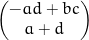

In [8]:
S.solP     # A**2 = -det(A) I + tr(A) A

## 2. La función `idioma`

El código LaTeX que genera NAcAL no contiene palabras, pero sí algunas representaciones de texto. `idioma('en')` las pone en inglés e `idioma('es')` vuelve al español (valor por defecto). Los mensajes de error no se traducen.

In [9]:
A = Matrix([[1,2],[2,4]]);  v = Vector([1,2])
print(idioma(), '->', repr(SEL(A, v)))
idioma('en')
print(idioma(), '->', repr(SEL(A, v)))
print(idioma(), '->', repr(Determinante(Matrix([[1,2],[3,4]]))))
idioma('es')

es -> Vector([1, 0]) + Combinaciones lineales de (Sistema([Vector([-2, 1]);]))
en -> Vector([1, 0]) + Linear combinations of (Sistema([Vector([-2, 1]);]))
en -> Value of the determinant: -2


## 3. Fallos corregidos en la 0.3.0

`InvMatF` e `InvMatFC` devolvían una matriz (que no era la inversa) cuando la matriz era singular. Ahora dan el mismo error que `InvMat`:

In [10]:
singular = Matrix([[1,2],[2,4]])
for inversa in (InvMat, InvMatF, InvMatFC):
    try:
        inversa(singular)
    except ValueError as error:
        print(inversa.__name__, '->', error)

InvMat -> Matrix es singular
InvMatF -> Matrix es singular
InvMatFC -> Matrix es singular


La representación de texto de un sistema sin solución es el conjunto vacío (antes era `set() + Combinaciones lineales de (...)`):

In [11]:
N = SEL(Matrix([[1,2],[2,4]]), Vector([1,3]))
print(repr(N))
N

set()


set()

## 4. La clase `Polinomio`

Un `Polinomio` es un `Vector` cuyos componentes son los coeficientes, de menor a mayor grado (sus coordenadas respecto de la base $1, x, x^2,\ldots$), pero se escribe como un polinomio. Se crea con una expresión o con la lista de coeficientes:

In [12]:
p = Polinomio((1-x)**2)
print(repr(p), '  coeficientes:', p.lista, '  grado:', p.grado())
print(repr(Polinomio([1,-2,1])))
p

Polinomio(1 - 2*x + x**2)   coeficientes: [1, -2, 1]   grado: 2
Polinomio(1 - 2*x + x**2)


Operaciones: suma y producto por números (también con polinomios de distinto grado), y producto de polinomios.

In [13]:
print(repr( 2*Polinomio(1+x) + Polinomio(x**3) ))
print(repr( Polinomio(1+x) * Polinomio(1-x) ))
print(Polinomio(1+x) == Polinomio([1,1,0]))

Polinomio(2 + 2*x + x**3)
Polinomio(1 - x**2)
True


Si los coeficientes son simbólicos hay que indicar cuál es la variable:

In [14]:
Polinomio(a*x**2 - (a+1)*x + 3, variable=x)

### Sistemas de ecuaciones con polinomios

¿Qué combinación lineal de $1$, $1+x$ y $(1+x)^2$ es igual a $3-2x+5x^2$? En la fila superior se ve cómo cambian los polinomios con cada transformación. El pivote de cada polinomio es el coeficiente de su término de menor grado (el primero que aparece escrito).

In [15]:
S = Sistema([ Polinomio(1), Polinomio(1+x), Polinomio((1+x)**2) ])
q = Polinomio(3 - 2*x + 5*x**2)
sol = SEL(S, q)
Math(desarrollo(sol, por_linea=2))

<IPython.core.display.Math object>

In [16]:
sol

Vector([10, -12, 5]) + Combinaciones lineales de (Sistema([Vector([0, 0, 0]);]))

In [17]:
S * sol.solP      # la combinación lineal con esos coeficientes

Un sistema sin solución: $x^2$ no es combinación lineal de $1$ y $x$.

In [18]:
SEL(Sistema([Polinomio(1), Polinomio(x)]), Polinomio(x**2), 1)

<IPython.core.display.Math object>

set()

### Dependencia lineal entre polinomios

`Homogenea` encuentra las combinaciones lineales nulas. Aquí $-(1+x)+(1-x)+2x=0$:

In [19]:
L = Sistema([ Polinomio(1+x), Polinomio(1-x), Polinomio(x), Polinomio(x**2) ])
H = Homogenea(L, 1)
H

<IPython.core.display.Math object>

Combinaciones lineales de (Sistema([Vector([-1, 1, 2, 0]);]))

In [20]:
L * (H.sgen|1)

### Eliminación con el término de menor o de mayor grado

`elim(0)` (o `Elim`) usa como pivote el término de menor grado y recorre el sistema de izquierda a derecha. La variante `elim(100)` (de atrás hacia delante) usa como pivote el término de mayor grado y recorre el sistema de derecha a izquierda.

In [21]:
B = Sistema([ Polinomio(1+x+x**2), Polinomio(1+2*x+x**2), Polinomio(1+x) ])
Math(B.fullcopy().elim(0).tex)

<IPython.core.display.Math object>

In [22]:
Math(B.fullcopy().elim(100).tex)

<IPython.core.display.Math object>